# Ancient Environmental Metagenomics (AEMG01)
## Day 4 · Part 2: Microbial contamination in eukaryotic reference genomes – the GENEX workflow

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day4_GENEX_shortcut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisite:** `Day1_setup_shortcut.ipynb` (`course_paths.json`). This notebook is independent of the samples analysed on Days 1–3.

### Learning outcomes
After this practical you will be able to:

* explain why eukaryotic reference genomes contain **microbial-like regions** and why that matters for sedimentary ancient DNA,
* run the **GENEX** workflow (GENome EXogenous sequence detection) on a reference genome,
* read its output: the **coordinates** (BED) of microbial-like regions and the **most abundant microbes** in each,
* inspect the regions in **IGV**, and **mask** them in the reference genome.

<p align="center">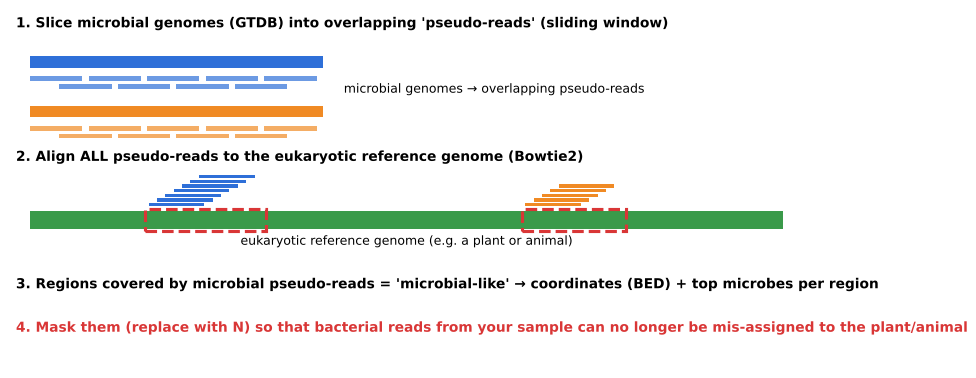<br><em>The idea of GENEX: microbial pseudo-reads that align to a eukaryotic genome reveal its microbial-like regions.</em></p>

---
## Scientific background: when the reference itself is contaminated

Detecting ancient **plants and animals** in sediments (sedaDNA) relies on large databases of **eukaryotic reference genomes**. But many eukaryotic genome assemblies contain regions that are highly similar to **bacterial or archaeal** DNA:

* **contamination** of the sequenced specimen or the assembly – bacteria living on or in the organism, or in the lab,
* **genuine biology** – horizontal gene transfer, endosymbionts integrated into the genome, conserved genes,
* **technical artefacts** – e.g. sequencing adapters left in an assembly (the carp example from Day 1 and Day 4 Part 1).

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/carpio.png" width="560"></p>

In an ancient sediment, the vast majority of reads are **microbial**. Even if only a tiny fraction of them aligns to a microbial-like region of, say, a plant genome, that can be enough to "detect" a plant that never grew there. Because microbial reads vastly outnumber eukaryotic ones, this is one of the main sources of **false-positive eukaryotic detections** in sedaDNA.

The solution is to **find these regions and mask them** (replace them by `N`) before using the genomes as references. The **GENEX** workflow (Oskolkov et al. 2025, *GigaScience*) does this:

1. it slices microbial genomes – from **GTDB v.214** or NCBI RefSeq – into overlapping **pseudo-reads** with a sliding window,
2. builds a **Bowtie2 index** of the eukaryotic reference genome and aligns **all** pseudo-reads to it,
3. detects the positions covered by pseudo-reads and reports them as **coordinates (BED)**, together with the **most abundant microbial species** in each region.

The authors applied it to nearly 3,000 eukaryotic reference genomes (vertebrates, invertebrates, plants) and found that microbial-like regions are widespread; the coordinates are available as a public resource (links at the end).

The full pseudo-read set contains **26 billion reads**; aligning it to e.g. a mammalian genome can take up to **48 hours** on a 20-core HPC node. The GENEX repository includes a **small subset of pseudo-reads and a small eukaryotic genome** for demonstration, which run in seconds – that's what we use today.

---
## 1. Session setup

### 1.1 Install conda
`condacolab.install()` restarts the kernel – the *"session crashed"* message is expected; continue with the next cell.

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

In [ ]:
import shutil, sys
mamba = shutil.which("mamba")
print("Python :", sys.executable)
print("mamba  :", mamba or "NOT FOUND")
assert mamba, "conda/mamba is not installed – run the condacolab.install() cell above and wait for the restart"
!mamba --version

### 1.2 Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### 1.3 Get the GENEX workflow

We clone the repository to the **local Colab disk** (`/content/MCWorkflow`), not to Drive: files on Drive cannot be made executable, and the workflow's scripts call each other; the local disk is also much faster. Results are copied to your Drive at the end.

* `git clone <url> <folder>` – download the repository,
* `git checkout 2fdf5da` – switch to the **first and most stable version** of the workflow, which this practical is written for (newer versions also offer a Nextflow implementation and slightly different arguments).

In [ ]:
%%bash
cd /content
[ -d MCWorkflow ] || git clone -q https://github.com/NikolayOskolkov/MCWorkflow
cd MCWorkflow
git checkout -q 2fdf5da
git log --oneline -1
ls
echo; echo "data folder:"; ls -lh data

### 1.4 Install the workflow's software

The repository defines its software in a conda environment file, `environment.yaml`. `mamba env create -n MCWorkflow -f environment.yaml` creates an environment called `MCWorkflow` with exactly these tools (Bowtie2, samtools and the other tools the workflow scripts call). If the file is missing, the cell falls back to installing the core tools by hand. In the main environment we additionally install **samtools** and **bedtools** (for indexing and masking the reference later), and **igv-notebook**.

In [ ]:
%%bash
cd /content/MCWorkflow
cat environment.yaml 2>/dev/null || echo "(no environment.yaml)"
if [ -f environment.yaml ]; then
    mamba env create -n MCWorkflow -f environment.yaml > /content/install_genex.log 2>&1
else
    mamba create -y -q -n MCWorkflow -c conda-forge -c bioconda bowtie2 samtools bedtools r-base > /content/install_genex.log 2>&1
fi
mamba install -y -q -c conda-forge -c bioconda samtools bedtools pandas > /content/install_base.log 2>&1
pip install -q igv-notebook
echo "done"

### 1.5 Paths and helpers

* `GENEX` – the workflow folder; `DATA` – its `data` folder with the eukaryotic reference and pseudo-reads,
* `RES` – where we save results in your Drive (`11_GENEX`),
* `ENVS` – conda environments; the workflow runs with `PATH=$ENVS/MCWorkflow/bin:$PATH` so that it finds its own tools.

`show_file()` displays HTML files inside the notebook – we use it for the workflow's **vignette**.

In [ ]:
import os, json, glob, subprocess, socket, time
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown
import pandas as pd, numpy as np, matplotlib.pyplot as plt

WORKDIR = "/content/drive/MyDrive/AEMG01"            # your own working folder (Day1_setup)
GENEX = "/content/MCWorkflow"
DATA = f"{GENEX}/data"
RES = f"{WORKDIR}/11_GENEX"
ENVS = subprocess.run(["conda", "info", "--base"], capture_output=True, text=True).stdout.strip() + "/envs"
os.makedirs(RES, exist_ok=True)
os.environ.update(WORKDIR=WORKDIR, GENEX=GENEX, DATA=DATA, RES=RES, ENVS=ENVS,
                  THREADS=str(os.cpu_count()), MPLBACKEND="Agg")

PORT = 8000
def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_file(path, height=700):
    """Show an HTML or PDF file (absolute path under /content) in an embedded frame."""
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", "/content"],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + os.path.relpath(path, "/content"), height=height)

for k in ["GENEX", "DATA", "RES", "ENVS", "THREADS"]:
    print(f"{k:8s}: {os.environ[k]}")
print("MCWorkflow environment:", "✅" if os.path.isdir(f"{ENVS}/MCWorkflow") else "❌ see /content/install_genex.log")

### 1.6 The vignette

The repository contains a detailed **vignette** describing the workflow, its parameters and the interpretation of its outputs. Let's open it inside the notebook – **read its preparation steps** before running the workflow.

In [ ]:
vig = sorted(glob.glob(f"{GENEX}/vignette*.html") + glob.glob(f"{GENEX}/*/vignette*.html"))
if vig:
    print("Showing", vig[0])
    show_file(vig[0], height=750)
else:
    print("No vignette.html found in this version – see https://github.com/NikolayOskolkov/MCWorkflow")

> If the vignette lists preparation steps for this version that are not covered by the next cells (e.g. decompressing or downloading a file into `data/`), run them here:

In [ ]:
%%bash
cd "${DATA:?DATA is not set - run cell 1.5 first}"
# put any extra preparation steps from the vignette here
ls -lh
echo; echo "workflow folder:"; ls -lh ..

---
## 2. Run GENEX

### 2.1 The command

```
./micr_cont_detect.sh REF_GENOME INPUT_DIR REFSEQ_OR_GTDB THREADS MICR_READS GTDB_ANNOT
```

| Argument | Our value | Meaning |
|---|---|---|
| `REF_GENOME` | `GCF_002220235.fna.gz` | the gzipped eukaryotic reference genome to screen (file name only, no path) |
| `INPUT_DIR` | `$DATA` | **absolute path** of the folder containing the reference |
| `REFSEQ_OR_GTDB` | `GTDB` | which kind of microbial pseudo-reads is used: `GTDB` or `RefSeq` |
| `THREADS` | `$THREADS` | number of CPU threads (2 on Colab) |
| `MICR_READS` | `GTDB_sliced_seqs_sliding_window.fna.gz` | the microbial pseudo-reads (file name only) – here the small demonstration subset |
| `GTDB_ANNOT` | `GTDB_fna2name.txt` | table translating GTDB genome IDs into species names |

The files live in two places: the **reference genome** in the `data` folder (`INPUT_DIR`), the **pseudo-reads** and **`GTDB_fna2name.txt`** in the workflow's main folder `/content/MCWorkflow` – which is why they are given by name only, and why we run the script from that folder.

First a quick check that all input files are in place; `zcat … | head -1` shows the first FASTA header of the reference and of the pseudo-reads (you can see the window coordinates in the pseudo-read names).

In [ ]:
%%bash
cd "${GENEX:?GENEX is not set - run cell 1.5 first}"
for f in data/GCF_002220235.fna.gz GTDB_sliced_seqs_sliding_window.fna.gz GTDB_fna2name.txt; do
    if [ -e "$f" ]; then echo "✅ $f ($(du -h $f | cut -f1))"; else echo "❌ $f missing"; fi
done
echo; echo "reference genome:"; zcat data/GCF_002220235.fna.gz | grep '>' | head -n 5
echo "number of sequences: $(zcat data/GCF_002220235.fna.gz | grep -c '>')"
echo; echo "pseudo-reads:"; zcat GTDB_sliced_seqs_sliding_window.fna.gz | head -n 2
echo "number of pseudo-reads: $(zcat GTDB_sliced_seqs_sliding_window.fna.gz | grep -c '>')"
echo; echo "GTDB annotation:"; head -n 3 GTDB_fna2name.txt

### 2.2 Run it

We run the script with `bash` from the workflow folder, with the `MCWorkflow` environment first on the `PATH`. For the demonstration data this takes seconds to a minute; for real genomes and the full 26-billion pseudo-read set, the alignment step dominates and **multi-threading is crucial**.

In [ ]:
%%bash
cd "${GENEX:?GENEX is not set - run cell 1.5 first}"
PATH=$ENVS/MCWorkflow/bin:$PATH bash micr_cont_detect.sh GCF_002220235.fna.gz $DATA GTDB $THREADS \
    GTDB_sliced_seqs_sliding_window.fna.gz GTDB_fna2name.txt 2>&1 | tail -n 25

---
## 3. Workflow outputs

First, the **Bowtie2 index** files (`*.bt2l`) of the eukaryotic reference are written into the `data` folder, and the verbose output of `bowtie2-build` goes to `bowtie2-build.log`. All main results are in the folder **`data/GCF_002220235.fna.gz_GTDB/`**:

In [ ]:
%%bash
cd "${DATA:?DATA is not set - run cell 1.5 first}"
ls -lh *.bt2l bowtie2-build.log 2>/dev/null
echo; echo "results folder:"; ls -lh GCF_002220235.fna.gz_GTDB/

### 3.1 Coordinates of microbial-like regions

The main output is **`coords_micr_contam_GCF_002220235.fna.gz.txt`**: the coordinates of microbial-like regions in **BED-like** format (despite the `.txt` extension). Its columns:

| # | Content |
|---|---|
| 1 | name (ID) of the eukaryotic reference genome |
| 2 | contig / scaffold / chromosome ID containing the microbial-like region |
| 3 | **start** coordinate of the region |
| 4 | **end** coordinate of the region |
| 5 | genomic **length** of the region |
| 6 | total number of pseudo-reads aligned to the region |
| 7 | average number of pseudo-reads supporting each position of the region |
| 8–12 | the **five most abundant microbial species** in the region, written as `N_reads_species`; if fewer than five microbes were found, the remaining columns contain `NA_reads_NA` |

In [ ]:
out_dir = f"{DATA}/GCF_002220235.fna.gz_GTDB"
coords_file = f"{out_dir}/coords_micr_contam_GCF_002220235.fna.gz.txt"
print("first lines of the file as written by GENEX:")
print("".join(open(coords_file).readlines()[:3]))

cols = ["genome", "contig", "start", "end", "length", "n_reads", "mean_reads_per_pos",
        "top1", "top2", "top3", "top4", "top5"]
first = [l for l in open(coords_file) if l.strip()][0]
coords = pd.read_csv(coords_file, sep="\t" if "\t" in first else r"\s+",     # tabs if present, else spaces
                     header=None, dtype=str, engine="python")
coords.columns = cols[:coords.shape[1]] + [f"extra{i}" for i in range(coords.shape[1] - len(cols))]

# drop a header line if there is one (its 'start' is not a number)
coords = coords[pd.to_numeric(coords["start"], errors="coerce").notna()].reset_index(drop=True)
for c in ["start", "end", "length", "n_reads", "mean_reads_per_pos"]:
    if c in coords:
        coords[c] = pd.to_numeric(coords[c], errors="coerce")

print(f"{len(coords)} microbial-like regions, {int(coords['length'].sum()):,} bp in total, "
      f"on {coords['contig'].nunique()} of the reference sequences")
coords.sort_values("n_reads", ascending=False).head(15)

How large is that compared with the genome? `samtools faidx` needs an uncompressed (or bgzip-compressed) FASTA, so we first write a decompressed copy to the results folder and index it; the `.fai` file lists every sequence with its length.

In [ ]:
%%bash
cd "${RES:?RES is not set - run cell 1.5 first}"
gunzip -c $DATA/GCF_002220235.fna.gz > GCF_002220235.fna
samtools faidx GCF_002220235.fna
echo "sequences: $(wc -l < GCF_002220235.fna.fai)   total length: $(awk '{s+=$2} END {print s}' GCF_002220235.fna.fai) bp"

In [ ]:
fai = pd.read_csv(f"{RES}/GCF_002220235.fna.fai", sep="\t", header=None, usecols=[0, 1], names=["contig", "contig_length"])
genome_len = fai.contig_length.sum()
print(f"microbial-like fraction of the genome: {100 * coords['length'].sum() / genome_len:.4f} %")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(coords["length"], bins=40, color="#D93636")
ax[0].set_xlabel("region length (bp)"); ax[0].set_ylabel("regions"); ax[0].set_title("Lengths of microbial-like regions")
per_contig = coords.groupby("contig")["length"].sum().sort_values(ascending=False).head(15)
per_contig.plot.barh(ax=ax[1], color="#2E6FD8"); ax[1].invert_yaxis()
ax[1].set_xlabel("bp in microbial-like regions"); ax[1].set_title("Top reference sequences")
plt.tight_layout(); plt.show()

### 3.2 Which microbes do these regions resemble?

The columns `top1`…`top5` contain entries like `25_reads_Escherichia_coli` – the number of pseudo-reads and the species, joined by `_reads_`. The function `parse_top` splits each entry at `_reads_` into a count and a species name (it accepts both orders), skips the `NA_reads_NA` placeholders, and we then sum the reads per species over all regions.

In [ ]:
def parse_top(v):
    # '25_reads_Escherichia_coli' (or 'Escherichia_coli_reads_25') -> ('Escherichia coli', 25)
    v = str(v)
    if "_reads_" not in v or "NA_reads_NA" in v:
        return None
    left, right = v.split("_reads_", 1)
    if left.isdigit():  return right.replace("_", " "), int(left)    # GENEX format: <count>_reads_<species>
    if right.isdigit(): return left.replace("_", " "), int(right)    # alternative order
    return None

records = [r for col in coords.columns if col.startswith("top")
           for r in map(parse_top, coords[col].dropna()) if r]
micr = pd.DataFrame(records, columns=["species", "reads"])
top = micr.groupby("species")["reads"].agg(["sum", "count"]).sort_values("sum", ascending=False)
top.columns = ["pseudo-reads", "regions"]
display(top.head(20))

top.head(15)["pseudo-reads"].plot.barh(figsize=(8, 5), color="#F08A24")
plt.gca().invert_yaxis(); plt.xlabel("pseudo-reads in microbial-like regions")
plt.title("Microbes most similar to regions of the reference"); plt.show()

❓ **Questions**
1. How many microbial-like regions were found, and what fraction of the genome do they cover?
2. Are the regions spread over many sequences or concentrated in a few (e.g. small unplaced scaffolds)? What could that tell you about their origin?
3. Which microbial taxa are most similar? Are they plausible contaminants of the sequenced specimen, or rather conserved genes shared by many bacteria?
4. How would the result change with the full GTDB pseudo-read set instead of the demonstration subset?

---
## 4. Look at the regions in IGV

We convert the coordinate file to a standard **BED** file for IGV – columns 2, 3, 4 (sequence, start, end), plus the most abundant microbe as the feature name – and display it on top of the eukaryotic reference (`fastaPath` / `indexPath` load the local FASTA and its `.fai`). If the workflow left an indexed BAM file of the pseudo-read alignments in its output folder, it is loaded as well, so you can see the stacks of microbial pseudo-reads.

> 💡 **Two practical notes on IGV in Colab.** (1) IGV reads files through the notebook, and reading them **directly from Google Drive** fails, so the helper `igv_local()` first **copies** the files it needs (BAM with its `.bai` index, FASTA with its `.fai` index) to Colab's local disk (`/content/igv`). (2) IGV takes **10–20 seconds** to appear the first time – wait before concluding that it is empty.

> BED coordinates are 0-based and half-open; if the workflow reports 1-based coordinates, the displayed regions are shifted by a single base – irrelevant at this scale.

In [ ]:
import os, shutil, igv_notebook

def igv_local(*paths, folder="/content/igv"):
    """Copy files (BAM + .bai, FASTA + .fai, BED, …) from Google Drive to Colab's local disk
    and return their new paths – IGV cannot read them reliably straight from Drive."""
    os.makedirs(folder, exist_ok=True)
    return [shutil.copy(p, os.path.join(folder, os.path.basename(p))) for p in paths]

igv_notebook.init()

bed = coords[["contig", "start", "end"]].copy()
bed["name"] = [(parse_top(v) or ("microbial-like", 0))[0] for v in coords["top1"]] if "top1" in coords else "microbial-like"
bed_file = f"{RES}/microbial_like_regions.bed"
bed.sort_values(["contig", "start"]).to_csv(bed_file, sep="\t", header=False, index=False)

r = coords.sort_values("n_reads", ascending=False).iloc[0]
locus = f"{r.contig}:{max(1, int(r.start) - 2000)}-{int(r.end) + 2000}"
fa, fai, bed_l = igv_local(f"{RES}/GCF_002220235.fna", f"{RES}/GCF_002220235.fna.fai", bed_file)
b = igv_notebook.Browser({
    "reference": {"id": "GCF_002220235", "name": "GCF_002220235", "fastaPath": fa, "indexPath": fai},
    "locus": locus})
b.load_track({"name": "microbial-like regions (GENEX)", "path": bed_l, "format": "bed", "type": "annotation"})

bams = [f for f in glob.glob(f"{out_dir}/*.bam") if os.path.exists(f + ".bai")]
if bams:
    bam_l, bai_l = igv_local(bams[0], bams[0] + ".bai")
    b.load_track({"name": "microbial pseudo-reads", "path": bam_l, "indexPath": bai_l,
                  "format": "bam", "type": "alignment"})
print("showing the region with most pseudo-reads:", locus, "| BAM loaded:", bool(bams))

Type other regions from the table in Section 3.1 into the IGV locus box, or zoom out to see how the regions are distributed along a sequence.

---
## 5. Mask the microbial-like regions

To use the genome as a reference for sedaDNA, we **mask** the microbial-like regions: every base inside them is replaced by `N`. Reads can no longer align to (or share k-mers with) these regions, so bacterial reads are no longer mis-assigned to the eukaryote – while the rest of the genome, and its coordinates, stay unchanged.

`bedtools maskfasta -fi <input FASTA> -bed <regions> -fo <output FASTA>` does exactly that. We count the `N`s before and after (`grep -v '>'` drops header lines, `tr -cd 'Nn'` deletes every character except N, `wc -c` counts what is left).

In [ ]:
%%bash
cd "${RES:?RES is not set - run cell 1.5 first}"
bedtools maskfasta -fi GCF_002220235.fna -bed microbial_like_regions.bed -fo GCF_002220235.masked.fna
echo "N before masking: $(grep -v '>' GCF_002220235.fna        | tr -cd 'Nn' | wc -c)"
echo "N after masking : $(grep -v '>' GCF_002220235.masked.fna | tr -cd 'Nn' | wc -c)"
gzip -f GCF_002220235.masked.fna
ls -lh

❓ Does the increase in `N`s match the total length of the regions? (Overlapping regions are only masked once.) What could be the **downside** of masking – think of genuine horizontal gene transfer or endosymbiont-derived genes of the eukaryote.

### Save the workflow output to your Drive

In [ ]:
%%bash
cp -r "${DATA:?run cell 1.5 first}/GCF_002220235.fna.gz_GTDB" $RES/
ls -lh $RES

---
## Summary

* Eukaryotic reference genomes contain **microbial-like regions** – from contamination, horizontal gene transfer or conserved genes – that cause **false-positive plant and animal detections** in microbe-rich sedimentary aDNA.
* **GENEX** finds them by aligning sliding-window **microbial pseudo-reads** (GTDB or RefSeq) to the eukaryotic genome and reporting covered regions as **BED coordinates** with their most similar microbes.
* **Masking** these regions (`bedtools maskfasta`) removes the problem while keeping the genome's coordinates.
* For real projects you rarely need to run GENEX yourself: **pre-computed coordinates** are available for thousands of reference genomes.

## Questions to think about
1. Why are false-positive *eukaryotic* detections a bigger problem in sediments than in, e.g., dental calculus?
2. Would you expect more microbial-like regions in chromosome-level or in scaffold-level assemblies? Why?
3. Besides masking, how else could you deal with reads hitting microbial-like regions?
4. How could the same idea be used to find **human-like** regions in microbial or other reference genomes?

## Resources
* GENEX / MCWorkflow: [github.com/NikolayOskolkov/MCWorkflow](https://github.com/NikolayOskolkov/MCWorkflow) · [WorkflowHub](https://workflowhub.eu/workflows/1846)
* Full pseudo-read datasets: SciLifeLab Figshare, [doi:10.17044/scilifelab.28491956](https://doi.org/10.17044/scilifelab.28491956)
* Pre-computed coordinates of microbial-like regions for thousands of eukaryotic genomes: [SciLifeLab Figshare](https://figshare.scilifelab.se/articles/dataset/Coordinates_of_microbial_contamination_in_eukaryotic_reference_genomes/28380476)
* Oskolkov N. et al. (2025) Improving taxonomic inference from ancient environmental metagenomes by masking microbial-like regions in reference genomes. *GigaScience* 14, [doi:10.1093/gigascience/giaf108](https://doi.org/10.1093/gigascience/giaf108)
* bedtools maskfasta: [bedtools.readthedocs.io](https://bedtools.readthedocs.io/en/latest/content/tools/maskfasta.html)

---
## Save this notebook as HTML

Finally, export the notebook – with all its outputs – to a single **HTML file** that you can open in any browser, keep as a record of your work, or share. [`jupyter nbconvert`](https://nbconvert.readthedocs.io/) converts the notebook file (`.ipynb`) to other formats; `--to html` selects HTML, and `--output-dir` writes the result into your own working folder (you cannot write into the instructor's shared folder).

1. **Save the notebook first** (*File ▸ Save*, or Ctrl/Cmd + S): nbconvert converts the file as it is stored in Google Drive.
2. Run the cell below. It looks for `Day4_GENEX_shortcut.ipynb` in your Drive (if you opened the notebook from GitHub, use *File ▸ Save a copy in Drive* first, or set `NB_PATH` by hand).

Interactive elements that need a running Colab session – embedded reports served by `show_html()` and IGV views – appear empty in the HTML file; tables, plots and printed output are kept.

In [ ]:
import glob, os, shutil, subprocess, sys
NB_NAME = "Day4_GENEX_shortcut.ipynb"
NB_PATH = None   # <- set by hand if the search below does not find the notebook

if NB_PATH is None:
    pats = [f"/content/drive/MyDrive/{NB_NAME}", f"/content/drive/MyDrive/*/{NB_NAME}",
            f"/content/drive/MyDrive/*/*/{NB_NAME}"]
    hits = [p for pat in pats for p in glob.glob(pat)]
    NB_PATH = max(hits, key=os.path.getmtime) if hits else None     # the most recently saved copy

OUT_DIR = os.environ.get("WORKDIR", "/content/drive/MyDrive/AEMG01")
if NB_PATH:
    print("converting", NB_PATH)
    # convert a local copy: nbconvert cannot cope with spaces in the path (e.g. "… (1)" shortcuts)
    os.makedirs("/content/nb_export", exist_ok=True)
    local_nb = shutil.copy(NB_PATH, f"/content/nb_export/{NB_NAME}")
    args = ["--to", "html", local_nb, "--output-dir", OUT_DIR]
    # use the `jupyter` command if it exists, otherwise nbconvert as a Python module
    cmd = ["jupyter", "nbconvert"] + args if shutil.which("jupyter") else [sys.executable, "-m", "nbconvert"] + args
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0 and "No module named nbconvert" in r.stderr:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nbconvert"])
        r = subprocess.run([sys.executable, "-m", "nbconvert"] + args, capture_output=True, text=True)
    print(r.stderr.strip().splitlines()[-1] if r.stderr.strip() else r.stdout)
    html = os.path.join(OUT_DIR, NB_NAME.replace(".ipynb", ".html"))
    print(("✅ HTML file: " if os.path.exists(html) else "❌ conversion failed – see the message above: ") + html)
else:
    print(f"{NB_NAME} not found in your Drive – save a copy in Drive (File ▸ Save a copy in Drive) or set NB_PATH")